# 06.7 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/07-tsne-umap/solutions.ipynb)

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
X_dig, y_dig = load_digits(return_X_y=True)
print(X_dig.shape)

(1797, 64)


## Exercise 1

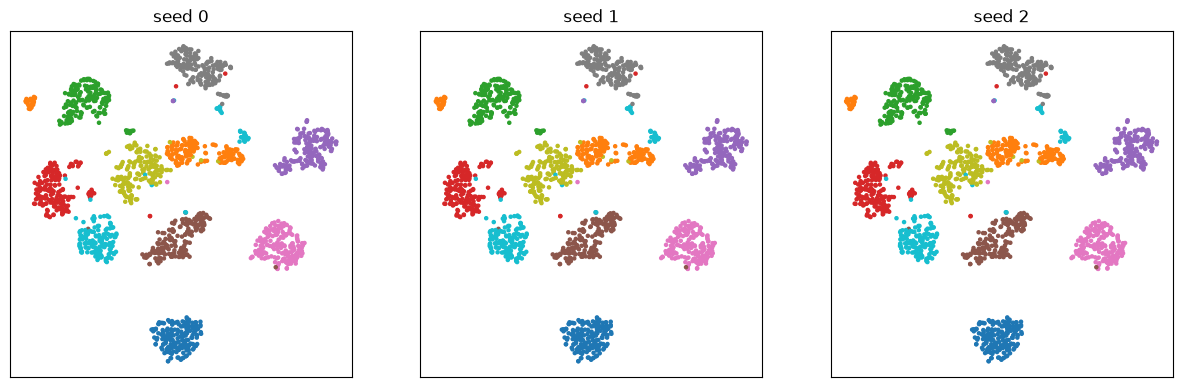

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, seed in zip(ax, [0, 1, 2]):
    xy = TSNE(perplexity=30, random_state=seed).fit_transform(X_dig)
    a.scatter(xy[:, 0], xy[:, 1], c=y_dig, cmap="tab10", s=5); a.set_title(f"seed {seed}")
    a.set_xticks([]); a.set_yticks([])
plt.show()

The **positions, orientation and spacing** of the islands change from seed to seed; the picture may even be mirrored. What stays stable is **which points sit together**: each digit still forms its own island, and the same few digits (often 1s, 8s and 9s) still have stragglers in other islands. Only local neighbourhoods are reliable.

## Exercise 2

In [3]:
import time
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

for name, data in [("t-SNE on 64 pixels", X_dig), ("PCA 30 -> t-SNE", PCA(30).fit_transform(X_dig))]:
    t0 = time.perf_counter()
    xy = TSNE(perplexity=30, random_state=0).fit_transform(data)
    secs = time.perf_counter() - t0
    acc = cross_val_score(KNeighborsClassifier(1), xy, y_dig, cv=5).mean()
    print(f"{name:>20}: {secs:4.1f} s, 1-NN agreement {acc:.1%}")

  t-SNE on 64 pixels:  1.6 s, 1-NN agreement 96.9%


     PCA 30 -> t-SNE:  1.6 s, 1-NN agreement 97.1%


On 1,797 digits both are quick and the pictures are about equally good, because 30 components keep about 96% of the variance (agreement 97.1% vs 96.9%). On wide data (thousands of columns) PCA first saves a lot of time and removes noise, which is why it is the usual recipe.

## Exercise 3

In [4]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"], **{"Customer ID": sales["Customer ID"].astype(int)})
print(f"{len(sales):,} clean transaction lines, {sales['Customer ID'].nunique():,} customers")

392,693 clean transaction lines, 4,338 customers


In [5]:
from sklearn.preprocessing import StandardScaler

snapshot = pd.Timestamp("2011-12-10")
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
rfm_scaled = pd.DataFrame(StandardScaler().fit_transform(np.log1p(rfm)), index=rfm.index, columns=rfm.columns)
print(f"{len(rfm):,} customers")
rfm.describe().round(1)

4,338 customers


,recency,frequency,monetary
count,4338.0,4338.0,4338.0
mean,92.1,4.3,2048.7
std,100.0,7.7,8985.2
min,0.0,1.0,3.8
25%,17.0,1.0,306.5
50%,50.0,2.0,668.6
75%,141.8,5.0,1660.6
max,373.0,209.0,280206.0


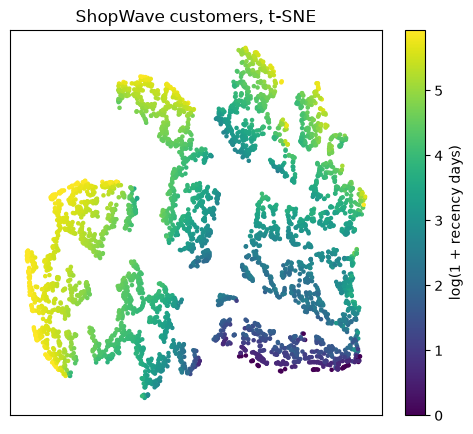

In [6]:
xy = TSNE(perplexity=30, random_state=0).fit_transform(rfm_scaled)
plt.figure(figsize=(6, 5))
sc = plt.scatter(xy[:, 0], xy[:, 1], c=np.log1p(rfm["recency"]), cmap="viridis", s=5)
plt.colorbar(sc, label="log(1 + recency days)"); plt.xticks([]); plt.yticks([])
plt.title("ShopWave customers, t-SNE"); plt.show()

Compare this with the digits. There, each digit was a tight island with empty space around it. Here there are no well-separated islands: the customers form loosely connected strands (t-SNE draws customers who share an exact order count as chains), and the colour changes **smoothly** from recent (dark) to lapsed (yellow) across the whole picture. That is an important finding. **Customer segments are a convenient way of cutting a continuum, not natural groups that exist in the data.** K-Means will always return k groups; whether they are real is a separate question (06.3).